# Online Sales Analysis

## Objective

### Analyze an online store sales dataset using Python and generate business insights through data cleaning, processing, analysis, and visualization.

## Scenario

### You are working as a Junior Data Analyst for an online store.

The company wants to understand:
Which products sell the most
Which city generates more revenue
Which category performs best
Monthly sales performance
Areas where sales can improve
Your job is to analyze the sales data and provide insights.


## part1- Data Loading

### Load the CSV dataset using Pandas

In [2]:
import pandas as pd
df = pd.read_excel("C:/Users/DELL/Desktop/New Folder/sales_data_2000_rows (2).xlsx")

In [3]:
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

### Check Dataset Information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  2000 non-null   int64  
 1   Date      2000 non-null   str    
 2   Product   2000 non-null   str    
 3   Category  2000 non-null   str    
 4   City      2000 non-null   str    
 5   Quantity  1999 non-null   float64
 6   Price     2000 non-null   int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 109.5 KB


## Part 2 — Data Cleaning

### Check missing values

In [6]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64

### Remove duplicate records

In [7]:
df.drop_duplicates

<bound method DataFrame.drop_duplicates of       Order_ID        Date   Product     Category       City  Quantity  Price
0         1001  2025-02-19   Printer  Electronics    Kolkata       3.0   9591
1         1002  2025-08-08       Pen   Stationery  Hyderabad       5.0    318
2         1003  2025-07-28     Mouse  Electronics    Chennai       1.0    697
3         1004  2025-08-15     Chair    Furniture  Ahmedabad       1.0   3410
4         1005  2025-04-12     Mouse  Electronics     Mumbai       NaN    624
...        ...         ...       ...          ...        ...       ...    ...
1995      2996  2025-12-26      Sofa    Furniture  Ahmedabad       4.0  15124
1996      2997  2025-02-27  Notebook   Stationery  Ahmedabad       3.0    160
1997      2998  2025-04-25     Chair    Furniture      Delhi       3.0   3590
1998      2999  2025-10-18   Monitor  Electronics     Mumbai       2.0   8550
1999      3000  2025-05-29       Bag  Accessories    Kolkata       5.0   1220

[2000 rows x 7 colum

### Correct spelling mistakes if any

In [8]:
from textblob import TextBlob
df 

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624
...,...,...,...,...,...,...,...
1995,2996,2025-12-26,Sofa,Furniture,Ahmedabad,4.0,15124
1996,2997,2025-02-27,Notebook,Stationery,Ahmedabad,3.0,160
1997,2998,2025-04-25,Chair,Furniture,Delhi,3.0,3590
1998,2999,2025-10-18,Monitor,Electronics,Mumbai,2.0,8550


### Convert Date column into datetime format

In [9]:
df['Date']=pd.to_datetime(df['Date'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  2000 non-null   int64         
 1   Date      2000 non-null   datetime64[us]
 2   Product   2000 non-null   str           
 3   Category  2000 non-null   str           
 4   City      2000 non-null   str           
 5   Quantity  1999 non-null   float64       
 6   Price     2000 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 109.5 KB


## part 3 - Data Processing

### create a revenue column

In [10]:
df['Revenue']=df['Quantity']*df['Price']
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624,NaN


## part 4 - Data Analysis

### Total sales revenue of the company

In [11]:
total_revenue = df['Revenue'].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 51500062.0


### Product with highest quantity sold

In [12]:
best_product = df.groupby('Product')['Quantity'].sum()
print("Best selling product:", best_product.idxmax())

Best selling product: Chair


### City with highest revenue

In [13]:
city_revenue = df.groupby('City')['Revenue'].sum()
print("Revenue by City:", city_revenue.idxmax())

Revenue by City: Ahmedabad


### Revenue generated by each category

In [14]:
category_revenue = df.groupby('Category')['Revenue'].sum()
print(category_revenue) 

Category
Accessories      905769.0
Electronics    37093350.0
Furniture      13343784.0
Stationery       157159.0
Name: Revenue, dtype: float64


### Total revenue generated per month

In [15]:
df['month'] = df['Date'].dt.to_period('M')
monthly_revenue = df.groupby('month')['Revenue'].sum()
print(monthly_revenue)

month
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4783602.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


## Part 5 - Data visualisation

### Bar Chart -Revenue by City

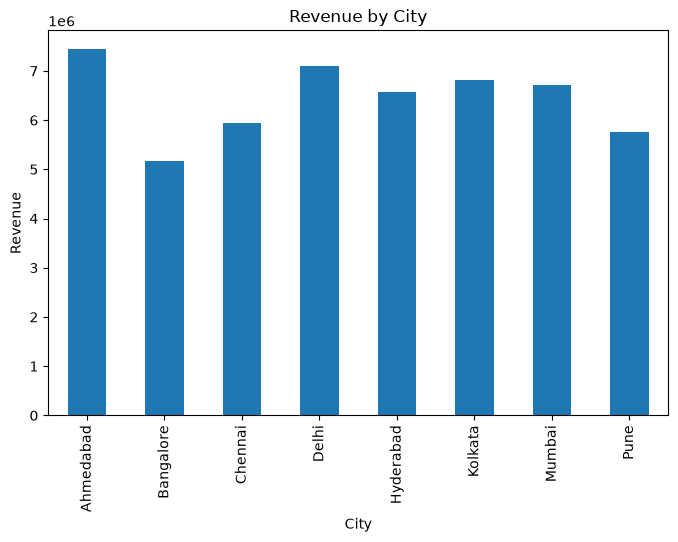

In [16]:
city_revenue.plot(kind='bar', figsize=(8,5))
plt.title('Revenue by City')
plt.xlabel('City')
plt.ylabel('Revenue')
plt.show()

### Pie Chart- Category contribution

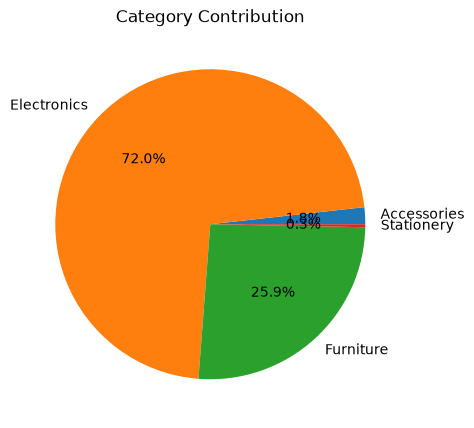

In [17]:
category_revenue.plot(kind='pie', autopct='%1.1f%%', figsize=(5,6))
plt.title('Category Contribution')
plt.ylabel('')
plt.show()

### Line Chart-  Monthly sales trend

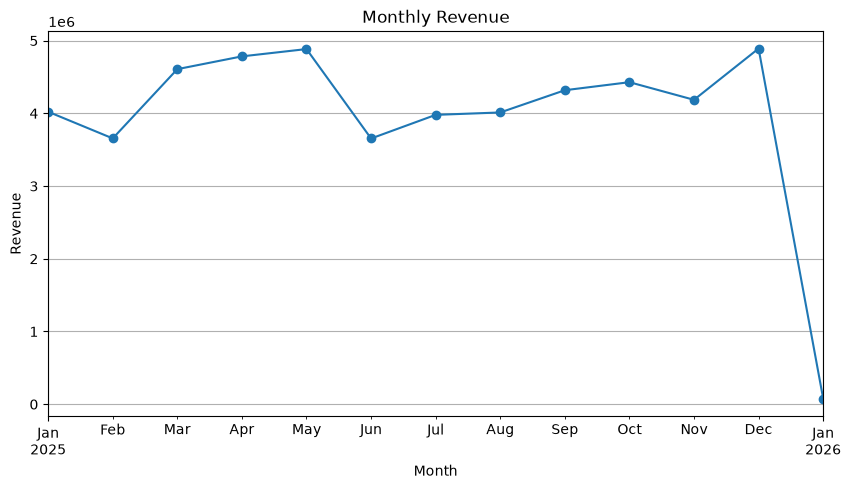

In [18]:
monthly_revenue.plot(kind='line', marker='o', figsize=(10,5))
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

## Part 6 — Business Insights

### Business insights
1.Ahmedabad has highest revenue

2.Electronics product sells frequently

3.Furniture generates higher revenue

4.Sales increased during May and December of 2025

5.The company generated total revenue of ₹51500062.0

## Part 7 — Recommendations

### Recommendations
1.Provide rewards and special offers to encourage customer purchases

2.Improve the promotions of products with low sales

3.Introduce combo offers to increase the average order value

## Bonus Task

### Find top 3 products by revenue

In [20]:
top_products = df.groupby('Product')['Revenue'].sum().sort_values(ascending=False).head(3)
print(top_products)

Product
Laptop     27105144.0
Sofa        8106368.0
Printer     4966315.0
Name: Revenue, dtype: float64


### Find average order value

In [21]:
average_order=df['Revenue'].mean()
print("Average Order Value:", average_order)

Average Order Value: 25762.912456228114


### Predict future sales using simple forecasting

In [22]:
monthly_sales = df.groupby('month')['Revenue'].sum()
average_sales = monthly_sales.mean()
print("Predicted Average Monthly Sales:", round(average_sales))

Predicted Average Monthly Sales: 3961543
